In [3]:
import duckdb

raw_glob = "/storage/vacoda/data/raw/api/single/**/*.csv"

con = duckdb.connect()

columns = con.execute(
    """
    DESCRIBE
    SELECT *
    FROM read_csv_auto(
        ?,
        union_by_name = true,
        sample_size = 100000
    )
    """,
    [raw_glob],
).df()

columns

,column_name,column_type,null,key,default,extra
0,TypeCode,VARCHAR,YES,None,None,None
1,FreqCode,VARCHAR,YES,None,None,None
2,RefPeriodId,BIGINT,YES,None,None,None
3,RefYear,BIGINT,YES,None,None,None
4,RefMonth,BIGINT,YES,None,None,None
5,Period,BIGINT,YES,None,None,None
6,ReporterCode,BIGINT,YES,None,None,None
7,ReporterISO,VARCHAR,YES,None,None,None
8,ReporterDesc,VARCHAR,YES,None,None,None
9,FlowCode,VARCHAR,YES,None,None,None


In [2]:
raw_codes = con.execute(
    """
    SELECT
        Period,
        ClassificationCode,
        CmdCode,
        ReporterISO,
        PartnerISO,
        FlowCode,
        NetWgt,
        PrimaryValue,
        IsReported,
        filename
    FROM read_csv_auto(
        ?,
        union_by_name = true,
        filename = true,
        sample_size = 100000
    )
    WHERE LPAD(CAST(CmdCode AS VARCHAR), 6, '0')
          IN ('440723', '440729')
    ORDER BY
        CmdCode,
        Period,
        ReporterISO,
        PartnerISO,
        FlowCode
    """,
    [raw_glob],
).df()

raw_codes

,Period,ClassificationCode,CmdCode,ReporterISO,PartnerISO,FlowCode,NetWgt,PrimaryValue,IsReported,filename
0,1988,H0,440723,AUS,BOL,M,16800.00,11644.000,False,/storage/vacoda/data/raw/api/single/comtrade_4...
1,1988,H0,440723,AUS,BRA,M,539000.00,478076.000,False,/storage/vacoda/data/raw/api/single/comtrade_4...
2,1988,H0,440723,AUS,CHL,M,16101.00,9321.000,False,/storage/vacoda/data/raw/api/single/comtrade_4...
3,1988,H0,440723,AUS,ECU,M,180601.00,105423.000,False,/storage/vacoda/data/raw/api/single/comtrade_4...
4,1988,H0,440723,AUS,FJI,M,174300.00,91877.000,False,/storage/vacoda/data/raw/api/single/comtrade_4...
...,...,...,...,...,...,...,...,...,...,...
274856,2025,H6,440729,ZAF,ZMB,M,0.00,41300.819,False,/storage/vacoda/data/raw/api/single/comtrade_4...
274857,2025,H6,440729,ZAF,ZMB,X,989.69,1489.305,False,/storage/vacoda/data/raw/api/single/comtrade_4...
274858,2025,H6,440729,ZAF,ZMB,X,989.69,1489.305,False,/storage/vacoda/data/raw/api/single/comtrade_4...
274859,2025,H6,440729,ZAF,ZMB,X,989.69,1489.305,False,/storage/vacoda/data/raw/api/single/comtrade_4...


In [3]:
code_identity = con.execute(
    """
    SELECT
        LPAD(CAST(CmdCode AS VARCHAR), 6, '0') AS raw_cmd,
        ClassificationCode                    AS raw_hs_version,
        MIN(Period)                            AS first_year,
        MAX(Period)                            AS last_year,
        COUNT(*)                               AS n_rows,
        COUNT(DISTINCT ReporterISO)             AS n_reporters,
        COUNT(DISTINCT PartnerISO)              AS n_partners,
        SUM(PrimaryValue)                       AS total_primary_value,
        SUM(NetWgt)                             AS total_net_weight
    FROM read_csv_auto(
        ?,
        union_by_name = true,
        sample_size = 100000
    )
    WHERE LPAD(CAST(CmdCode AS VARCHAR), 6, '0')
          IN ('440723', '440729')
    GROUP BY
        raw_cmd,
        raw_hs_version
    ORDER BY
        raw_cmd,
        first_year
    """,
    [raw_glob],
).df()

code_identity

,raw_cmd,raw_hs_version,first_year,last_year,n_rows,n_reporters,n_partners,total_primary_value,total_net_weight
0,440723,H0,1988,2007,4587,114,183,3.490244e+09,6.962464e+09
1,440723,H6,2022,2025,12595,102,157,5.161818e+09,3.647067e+09
2,440729,H1,1996,2014,22068,160,225,3.493254e+10,2.693807e+11
3,440729,H2,2002,2018,37699,162,230,6.634464e+10,7.575442e+10
4,440729,H3,2007,2025,39419,165,231,5.438154e+10,6.169820e+10
5,440729,H4,2012,2024,41961,166,226,4.465574e+10,5.000950e+10
6,440729,H5,2017,2025,67115,165,224,1.536156e+11,2.484130e+11
7,440729,H6,2022,2025,49417,139,216,1.054855e+11,2.280068e+11


In [4]:
files_with_codes = con.execute(
    """
    SELECT
        LPAD(CAST(CmdCode AS VARCHAR), 6, '0') AS raw_cmd,
        ClassificationCode,
        Period,
        filename,
        COUNT(*) AS n_rows
    FROM read_csv_auto(
        ?,
        union_by_name = true,
        filename = true,
        sample_size = 100000
    )
    WHERE LPAD(CAST(CmdCode AS VARCHAR), 6, '0')
          IN ('440723', '440729')
    GROUP BY
        raw_cmd,
        ClassificationCode,
        Period,
        filename
    ORDER BY
        raw_cmd,
        Period,
        filename
    """,
    [raw_glob],
).df()

files_with_codes

,raw_cmd,ClassificationCode,Period,filename,n_rows
0,440723,H0,1988,/storage/vacoda/data/raw/api/single/comtrade_4...,147
1,440723,H0,1989,/storage/vacoda/data/raw/api/single/comtrade_4...,301
2,440723,H0,1990,/storage/vacoda/data/raw/api/single/comtrade_4...,317
3,440723,H0,1991,/storage/vacoda/data/raw/api/single/comtrade_4...,401
4,440723,H0,1992,/storage/vacoda/data/raw/api/single/comtrade_4...,493
...,...,...,...,...,...
100,440729,H3,2024,/storage/vacoda/data/raw/api/single/comtrade_4...,46
101,440729,H5,2024,/storage/vacoda/data/raw/api/single/comtrade_4...,130
102,440729,H3,2025,/storage/vacoda/data/raw/api/single/comtrade_4...,4
103,440729,H6,2025,/storage/vacoda/data/raw/api/single/comtrade_4...,8576


In [5]:
files_with_codes = con.execute(
    """
    SELECT
        LPAD(CAST(CmdCode AS VARCHAR), 6, '0') AS raw_cmd,
        ClassificationCode,
        Period,
        regexp_extract(filename, '[^/]+$') AS file_name,
        COUNT(*) AS n_rows
    FROM read_csv_auto(
        ?,
        union_by_name = true,
        filename = true,
        sample_size = 100000
    )
    WHERE LPAD(CAST(CmdCode AS VARCHAR), 6, '0')
          IN ('440723', '440729')
    GROUP BY
        raw_cmd,
        ClassificationCode,
        Period,
        file_name
    ORDER BY
        raw_cmd,
        Period,
        ClassificationCode,
        file_name
    """,
    [raw_glob],
).df()

In [6]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

files_with_codes.head(30)

,raw_cmd,ClassificationCode,Period,file_name,n_rows
0,440723,H0,1988,comtrade_440723_1988.csv,147
1,440723,H0,1989,comtrade_440723_1989.csv,301
2,440723,H0,1990,comtrade_440723_1990.csv,317
3,440723,H0,1991,comtrade_440723_1991.csv,401
4,440723,H0,1992,comtrade_440723_1992.csv,493
5,440723,H0,1993,comtrade_440723_1993.csv,617
6,440723,H0,1994,comtrade_440723_1994.csv,800
7,440723,H0,1995,comtrade_440723_1995.csv,887
8,440723,H0,1996,comtrade_440723_1996.csv,262
9,440723,H0,1997,comtrade_440723_1997.csv,82


In [4]:
h6_440729_files = con.execute(
    """
    SELECT
        filename,
        Period,
        COUNT(*) AS n_rows
    FROM read_csv_auto(
        ?,
        union_by_name = true,
        filename = true,
        sample_size = -1
    )
    WHERE LPAD(CAST(CmdCode AS VARCHAR), 6, '0') = '440729'
      AND ClassificationCode = 'H6'
    GROUP BY filename, Period
    ORDER BY Period, filename
    """,
    [raw_glob],
).df()

print(h6_440729_files.to_string(index=False))

                                                    filename  Period  n_rows
/storage/vacoda/data/raw/api/single/comtrade_440729_2022.csv    2022   13869
/storage/vacoda/data/raw/api/single/comtrade_440729_2023.csv    2023   13519
/storage/vacoda/data/raw/api/single/comtrade_440729_2024.csv    2024   13453
/storage/vacoda/data/raw/api/single/comtrade_440729_2025.csv    2025    8576


In [5]:
file_path = (
    "/storage/vacoda/data/raw/api/single/"
    "comtrade_440729_2025.csv"
)

evidence = con.execute(
    """
    SELECT
        Period,
        ClassificationCode,
        CmdCode,
        ReporterISO,
        PartnerISO,
        FlowCode,
        PrimaryValue,
        NetWgt
    FROM read_csv_auto(
        ?,
        sample_size = -1
    )
    WHERE LPAD(CAST(CmdCode AS VARCHAR), 6, '0') = '440729'
      AND ClassificationCode = 'H6'
    LIMIT 20
    """,
    [file_path],
).df()

print(evidence.to_string(index=False))

 Period ClassificationCode  CmdCode ReporterISO PartnerISO FlowCode  PrimaryValue    NetWgt
   2025                 H6   440729         BLZ        FRA        X      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA        X      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA        X      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA        X      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA       DX      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA       DX      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA       DX      62573.50 10204.300
   2025                 H6   440729         BLZ        FRA       DX      62573.50 10204.300
   2025                 H6   440729         BLZ        USA        X      96997.85 11366.721
   2025                 H6   440729         BLZ        USA        X      96997.8

## Product-group

In [1]:
import pandas as pd

path = "/storage/vacoda/data/interim/cif_fob/target_h5/target_h5_cif_fob_training_sample.parquet"

df = pd.read_parquet(path)

print(df.columns.tolist())

['year', 'exporter_iso', 'importer_iso', 'target_cmd', 'export_value_fob', 'import_value_cif', 'export_weight_kg_pre_allocation', 'import_weight_kg_pre_allocation', 'export_weight_kg', 'import_weight_kg', 'export_weight_source', 'import_weight_source', 'export_weight_estimated', 'import_weight_estimated', 'export_weight_is_proxy', 'import_weight_is_proxy', 'import_direct_cif_value', 'import_direct_fob_value', 'import_direct_cif_fob_factor', 'import_direct_covered_primary_value', 'import_direct_value_coverage', 'import_direct_pair_component_count', 'export_component_row_count', 'import_component_row_count', 'export_partner2_count', 'import_partner2_count', 'export_mot_count', 'import_mot_count', 'export_customs_count', 'import_customs_count', 'export_mos_count', 'import_mos_count', 'export_source_hs_count', 'import_source_hs_count', 'export_source_cmd_count', 'import_source_cmd_count', 'export_source_cmd_original_count', 'import_source_cmd_original_count', 'export_estimated_weight_compo

In [2]:
"product_group" in df.columns

False

In [3]:
[c for c in df.columns if "cmd" in c.lower() or "hs" in c.lower()]

['target_cmd',
 'export_source_hs_count',
 'import_source_hs_count',
 'export_source_cmd_count',
 'import_source_cmd_count',
 'export_source_cmd_original_count',
 'import_source_cmd_original_count']

In [4]:
df["hs4_product_group"] = (
    df["target_cmd"]
    .astype(str)
    .str.zfill(6)
    .str[:4]
)

In [5]:
df[["target_cmd", "hs4_product_group"]].drop_duplicates().head(5)

,target_cmd,hs4_product_group
0,441239,4412
28,441875,4418
64,441879,4418
65,441873,4418
133,480258,4802


In [6]:
df["hs4_product_group"].nunique()

86

In [7]:
df["hs4_product_group"].value_counts().head(10)

hs4_product_group
9403    297304
4819    288035
4820    216147
4802    212580
4911    208659
4823    200914
9401    185533
4811    184448
4901    178316
4418    174339
Name: count, dtype: int64

In [8]:
df["hs4_product_group"].value_counts().tail(20)

hs4_product_group
4904    11901
5504    11685
5510    11349
3921    11259
5502     8395
4406     7226
4405     7058
5508     6873
4704     6579
5511     6297
9620     5240
4701     4434
4702     4236
4705     4040
5405     3914
5507     3553
5505     2262
9619      882
3006       19
5406        8
Name: count, dtype: int64

## CIF/FOB Distribution

/home/saxena/Projects/venvs/vacoda-venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


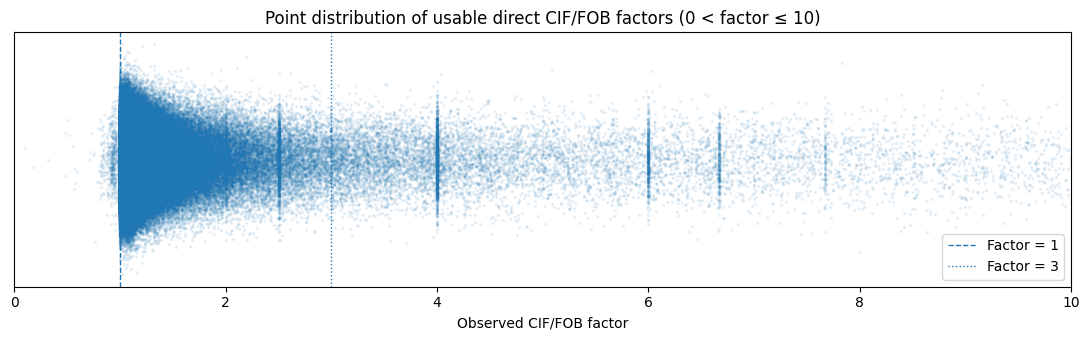

In [1]:
import duckdb
import numpy as np
import matplotlib.pyplot as plt

path = "/storage/vacoda/data/interim/cif_fob/target_h5/target_h5_cif_fob_training_sample.parquet"

query = f"""
SELECT
    observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND observed_cif_fob_factor <= 10
  AND has_import_direct_factor = TRUE
"""

df_10 = duckdb.query(query).df()

x = df_10["observed_cif_fob_factor"].to_numpy()

# vertical jitter only for visibility
rng = np.random.default_rng(42)
y = rng.normal(loc=0, scale=0.06, size=len(x))

plt.figure(figsize=(11, 3.5))
plt.scatter(x, y, s=2, alpha=0.08)
plt.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1")
plt.axvline(3.0, linestyle=":", linewidth=1, label="Factor = 3")
plt.xlim(0, 10)
plt.yticks([])
plt.xlabel("Observed CIF/FOB factor")
plt.title("Point distribution of usable direct CIF/FOB factors (0 < factor ≤ 10)")
plt.legend()
plt.tight_layout()
plt.show()

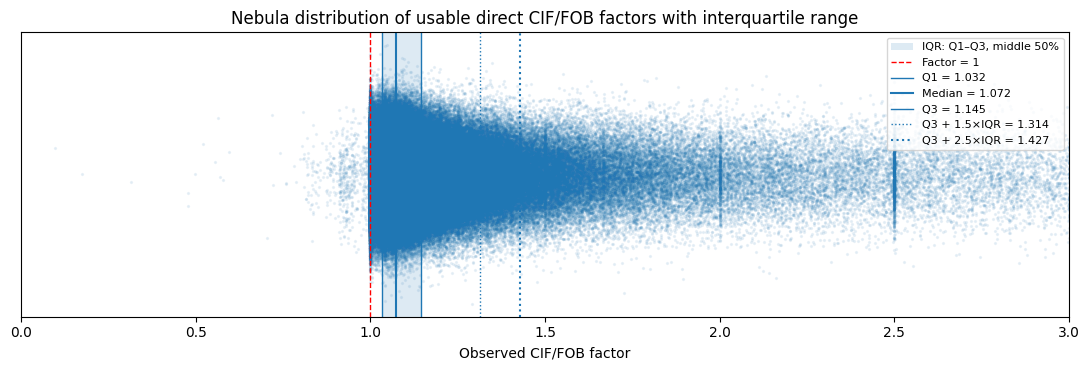

In [1]:
import duckdb
import numpy as np
import matplotlib.pyplot as plt

path = "/storage/vacoda/data/interim/cif_fob/target_h5/target_h5_cif_fob_training_sample.parquet"

query = f"""
SELECT
    observed_cif_fob_factor,
    log_observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND observed_cif_fob_factor <= 3
  AND log_observed_cif_fob_factor IS NOT NULL
  AND has_import_direct_factor = TRUE
"""

df_10 = duckdb.query(query).df()

x = df_10["observed_cif_fob_factor"].to_numpy()

# vertical jitter for nebula effect
rng = np.random.default_rng(42)
y = rng.normal(loc=0, scale=0.06, size=len(x))

# Quartiles on raw factor scale
q1 = df_10["observed_cif_fob_factor"].quantile(0.25)
median = df_10["observed_cif_fob_factor"].quantile(0.50)
q3 = df_10["observed_cif_fob_factor"].quantile(0.75)
iqr = q3 - q1

upper_15_iqr = q3 + 1.5 * iqr
upper_25_iqr = q3 + 2.5 * iqr

plt.figure(figsize=(11, 3.8))

# Shaded interquartile range: Q1 to Q3
plt.axvspan(q1, q3, alpha=0.15, label="IQR: Q1–Q3, middle 50%")

# Nebula points
plt.scatter(x, y, s=2, alpha=0.08)

# Reference lines
plt.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1", color="red")
plt.axvline(q1, linestyle="-", linewidth=1, label=f"Q1 = {q1:.3f}")
plt.axvline(median, linestyle="-", linewidth=1.5, label=f"Median = {median:.3f}")
plt.axvline(q3, linestyle="-", linewidth=1, label=f"Q3 = {q3:.3f}")

# IQR outlier-style limits
plt.axvline(upper_15_iqr, linestyle=":", linewidth=1, label=f"Q3 + 1.5×IQR = {upper_15_iqr:.3f}")
plt.axvline(upper_25_iqr, linestyle=":", linewidth=1.5, label=f"Q3 + 2.5×IQR = {upper_25_iqr:.3f}")

plt.xlim(0, 3)
plt.yticks([])
plt.xlabel("Observed CIF/FOB factor")
plt.title("Nebula distribution of usable direct CIF/FOB factors with interquartile range")
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

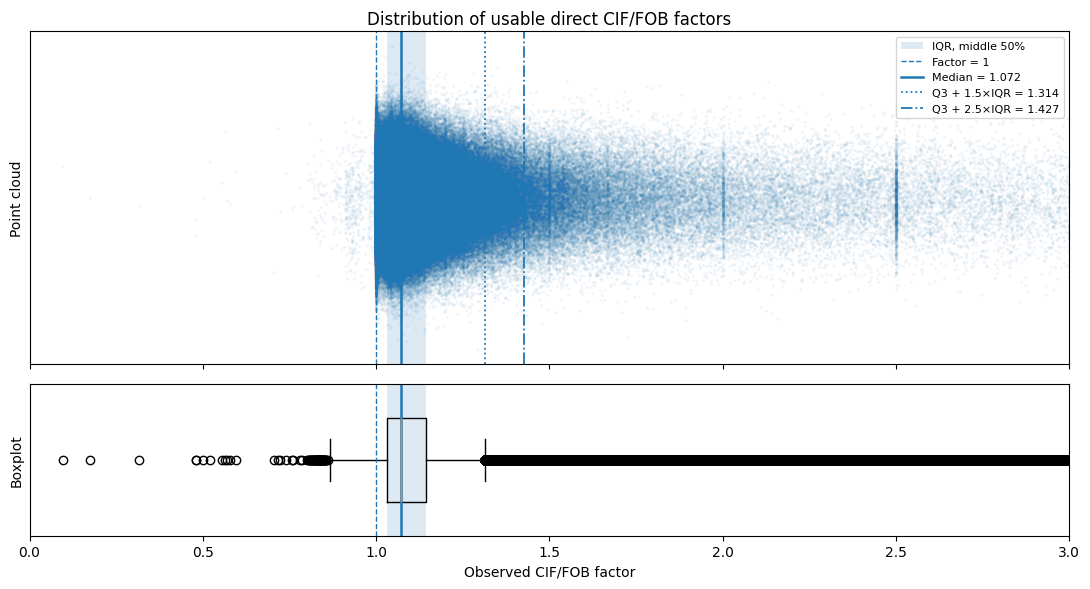

In [2]:
import duckdb
import numpy as np
import matplotlib.pyplot as plt

path = "/storage/vacoda/data/interim/cif_fob/target_h5/target_h5_cif_fob_training_sample.parquet"

query = f"""
SELECT
    observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND observed_cif_fob_factor <= 3
  AND has_import_direct_factor = TRUE
"""

df_plot = duckdb.query(query).df()
x = df_plot["observed_cif_fob_factor"].to_numpy()

# quartiles
q1 = np.quantile(x, 0.25)
median = np.quantile(x, 0.50)
q3 = np.quantile(x, 0.75)
iqr = q3 - q1

upper_15_iqr = q3 + 1.5 * iqr
upper_25_iqr = q3 + 2.5 * iqr

# jitter
rng = np.random.default_rng(42)
y = rng.normal(loc=0, scale=0.055, size=len(x))

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(11, 6),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1]}
)

# -------------------------
# Top: nebula / point cloud
# -------------------------
ax1.axvspan(q1, q3, alpha=0.15, label="IQR, middle 50%")
ax1.scatter(x, y, s=2, alpha=0.04)

ax1.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1")
ax1.axvline(median, linestyle="-", linewidth=1.8, label=f"Median = {median:.3f}")
ax1.axvline(upper_15_iqr, linestyle=":", linewidth=1.3, label=f"Q3 + 1.5×IQR = {upper_15_iqr:.3f}")
ax1.axvline(upper_25_iqr, linestyle="-.", linewidth=1.3, label=f"Q3 + 2.5×IQR = {upper_25_iqr:.3f}")

ax1.set_yticks([])
ax1.set_ylabel("Point cloud")
ax1.set_title("Distribution of usable direct CIF/FOB factors")
ax1.legend(loc="upper right", fontsize=8, frameon=True)

# -------------------------
# Bottom: boxplot
# -------------------------
ax2.boxplot(
    x,
    vert=False,
    showfliers=True,
    widths=0.55
)

ax2.axvline(1.0, linestyle="--", linewidth=1)
ax2.axvspan(q1, q3, alpha=0.15)
ax2.axvline(median, linestyle="-", linewidth=1.8)

ax2.set_yticks([])
ax2.set_xlabel("Observed CIF/FOB factor")
ax2.set_ylabel("Boxplot")

# shared formatting
ax2.set_xlim(0, 3)

plt.tight_layout()
plt.show()

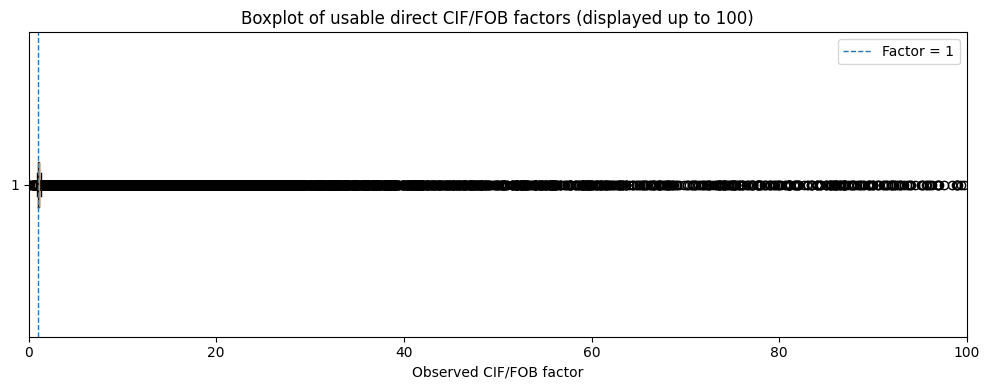

In [1]:
import duckdb
import matplotlib.pyplot as plt

path = "/storage/vacoda/data/interim/cif_fob/target_h5/target_h5_cif_fob_training_sample.parquet"

query = f"""
SELECT observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND has_import_direct_factor = TRUE
  AND observed_cif_fob_factor <= 100
"""

df_box_100 = duckdb.query(query).df()

plt.figure(figsize=(10, 4))
plt.boxplot(df_box_100["observed_cif_fob_factor"], vert=False, showfliers=True)
plt.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1")
plt.xlim(0, 100)
plt.xlabel("Observed CIF/FOB factor")
plt.title("Boxplot of usable direct CIF/FOB factors (displayed up to 100)")
plt.legend()
plt.tight_layout()
plt.show()

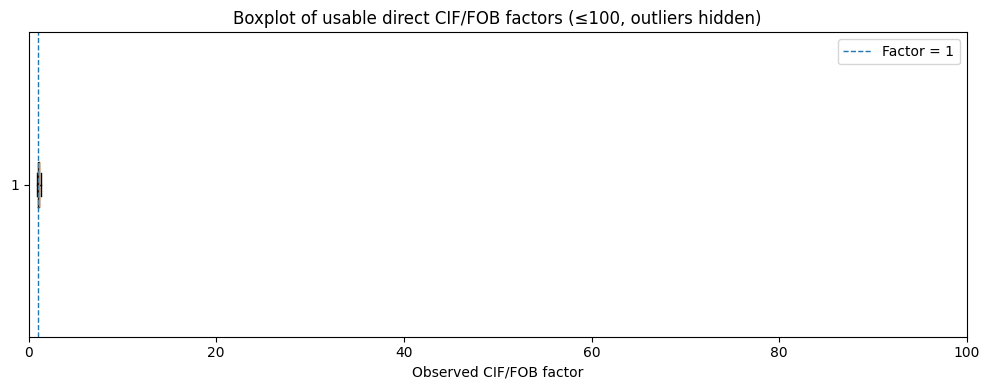

In [2]:
plt.figure(figsize=(10, 4))
plt.boxplot(df_box_100["observed_cif_fob_factor"], vert=False, showfliers=False)
plt.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1")
plt.xlim(0, 100)
plt.xlabel("Observed CIF/FOB factor")
plt.title("Boxplot of usable direct CIF/FOB factors (≤100, outliers hidden)")
plt.legend()
plt.tight_layout()
plt.show()

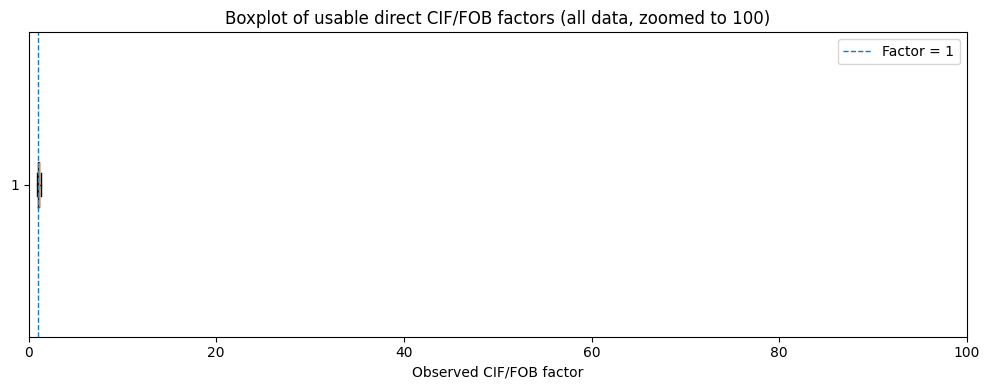

In [3]:
query_all = f"""
SELECT observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND has_import_direct_factor = TRUE
"""

df_all = duckdb.query(query_all).df()

plt.figure(figsize=(10, 4))
plt.boxplot(df_all["observed_cif_fob_factor"], vert=False, showfliers=False)
plt.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1")
plt.xlim(0, 100)
plt.xlabel("Observed CIF/FOB factor")
plt.title("Boxplot of usable direct CIF/FOB factors (all data, zoomed to 100)")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
df_box_100["observed_cif_fob_factor"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    682192.000000
mean          1.352608
std           2.503347
min           0.096316
50%           1.074095
75%           1.154162
90%           1.354056
95%           1.711288
99%           6.066052
max          99.696718
Name: observed_cif_fob_factor, dtype: float64

In [6]:
df_all["observed_cif_fob_factor"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    6.827400e+05
mean     6.709949e+00
std      3.016934e+03
min      9.631625e-02
50%      1.074108e+00
75%      1.154546e+00
90%      1.356502e+00
95%      1.723224e+00
99%      6.661021e+00
max      2.483945e+06
Name: observed_cif_fob_factor, dtype: float64

In [7]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path = "/storage/vacoda/data/interim/cif_fob/target_h5/target_h5_cif_fob_training_sample.parquet"

query = f"""
SELECT
    year,
    exporter_iso,
    importer_iso,
    target_cmd,
    observed_cif_fob_factor,
    log_observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND has_import_direct_factor = TRUE
"""

df = duckdb.query(query).df()

print("Number of usable direct-factor cases:", len(df))
df.head()

Number of usable direct-factor cases: 682740


,year,exporter_iso,importer_iso,target_cmd,observed_cif_fob_factor,log_observed_cif_fob_factor
0,2020,GBR,BOL,491191,1.085419,0.081966
1,2024,DEU,PHL,940340,1.088063,0.084399
2,2024,MKD,SVK,940340,1.074627,0.071974
3,2024,JPN,USA,940340,1.062357,0.060490
4,2017,IDN,BRA,940350,1.179590,0.165167


In [8]:
query = f"""
SELECT
    observed_cif_fob_factor,
    log_observed_cif_fob_factor
FROM read_parquet('{path}')
WHERE observed_cif_fob_factor IS NOT NULL
  AND observed_cif_fob_factor > 0
  AND has_import_direct_factor = TRUE
"""

df = duckdb.query(query).df()

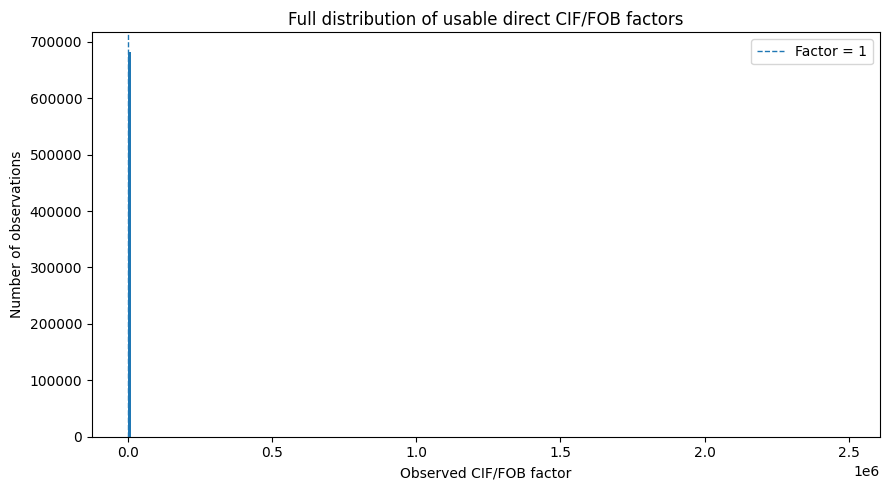

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(df["observed_cif_fob_factor"], bins=200)
plt.axvline(1.0, linestyle="--", linewidth=1, label="Factor = 1")
plt.xlabel("Observed CIF/FOB factor")
plt.ylabel("Number of observations")
plt.title("Full distribution of usable direct CIF/FOB factors")
plt.legend()
plt.tight_layout()
plt.show()

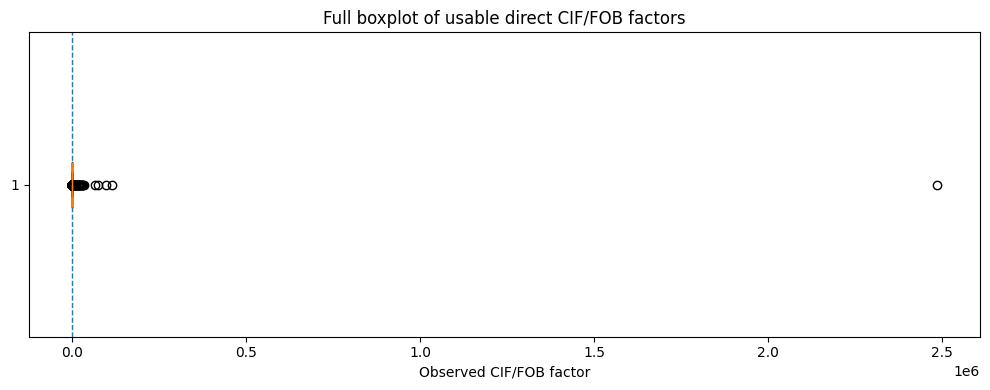

In [10]:
plt.figure(figsize=(10, 4))
plt.boxplot(df["observed_cif_fob_factor"], vert=False, showfliers=True)
plt.axvline(1.0, linestyle="--", linewidth=1)
plt.xlabel("Observed CIF/FOB factor")
plt.title("Full boxplot of usable direct CIF/FOB factors")
plt.tight_layout()
plt.show()

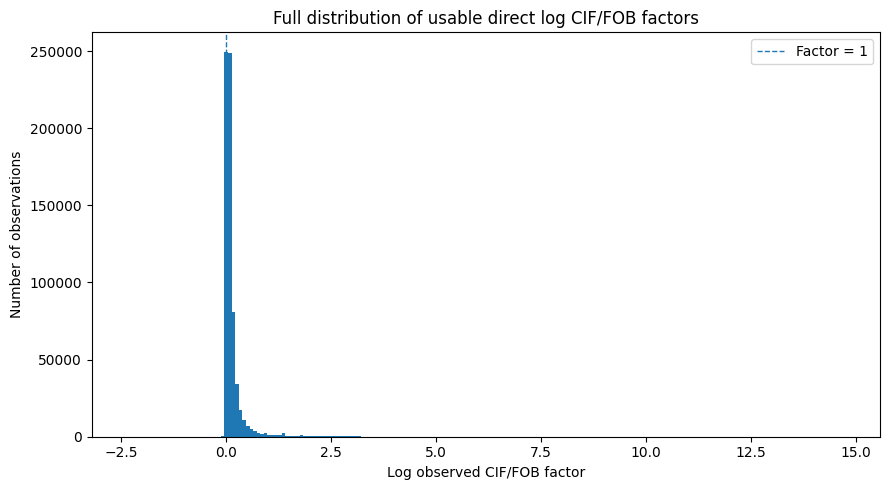

In [11]:
plt.figure(figsize=(9, 5))
plt.hist(df["log_observed_cif_fob_factor"], bins=200)
plt.axvline(0.0, linestyle="--", linewidth=1, label="Factor = 1")
plt.xlabel("Log observed CIF/FOB factor")
plt.ylabel("Number of observations")
plt.title("Full distribution of usable direct log CIF/FOB factors")
plt.legend()
plt.tight_layout()
plt.show()